# E. coli urinary resistance, 2020–2023

Do apparent trends in WHO GLASS data survive holding the reporting countries,
and their testing volumes, fixed? Three first-line UTI antibiotics:
ciprofloxacin, co-trimoxazole, cefotaxime.

## 1. Load the four GLASS exports

Each export has three stacked blocks; the analysis block is found by its marker
rather than a hard-coded line number. The year comes from the filename.

In [1]:
import re
from pathlib import Path
import pandas as pd

DATA = Path("../data")
MARKER = "Data for boxplots"

def find_data_block(path):
    """How many lines to skip before the data block's header row."""
    with open(path, encoding="utf-8-sig") as f:
        for i, line in enumerate(f):
            if line.strip().startswith(MARKER):
                return i + 1
    raise ValueError(f"marker not found in {path.name}")

def year_from_name(path):
    """Pull the four-digit year out of the filename."""
    match = re.search(r"(20\d\d)", path.name)
    if match is None:
        raise ValueError(f"no year in {path.name}")
    return int(match.group(1))

In [2]:
paths = sorted(DATA.glob("*.csv"))
if not paths:
    raise FileNotFoundError(f"no CSV files in {DATA.resolve()}")

frames = []
for path in paths:
    skip = find_data_block(path)
    df = pd.read_csv(path, skiprows=skip, encoding="utf-8-sig")
    df["Year"] = year_from_name(path)
    frames.append(df)
    print(f"{path.name:<52} skip {skip:>3}  rows {len(df):>4}  year {df['Year'].iloc[0]}")

amr = pd.concat(frames, ignore_index=True)
print("\ncombined shape:", amr.shape)
amr.head()

Resistance to antibiotics in 2020_All-Urinary tract.csv skip  40  rows  552  year 2020
Resistance to antibiotics in 2021_All-Urinary tract.csv skip  40  rows  545  year 2021
Resistance to antibiotics in 2022_All-Urinary tract.csv skip  40  rows  553  year 2022
Resistance to antibiotics in 2023_All-Urinary tract.csv skip  40  rows  650  year 2023

combined shape: (2300, 10)


,Specimen,PathogenName,AntibioticName,Iso3,CountryTerritoryArea,WHORegionName,InterpretableAST,Resistant,ResistancePercentage,Year
0,Urinary tract,Escherichia coli,Ceftriaxone,AFG,Afghanistan,Eastern Mediterranean Region,34,26,76.470588,2020
1,Urinary tract,Escherichia coli,Co-trimoxazole,AFG,Afghanistan,Eastern Mediterranean Region,13,12,92.307692,2020
2,Urinary tract,Escherichia coli,Colistin,AFG,Afghanistan,Eastern Mediterranean Region,23,7,30.434783,2020
3,Urinary tract,Escherichia coli,Doripenem,AFG,Afghanistan,Eastern Mediterranean Region,15,3,20.000000,2020
4,Urinary tract,Escherichia coli,Ertapenem,AFG,Afghanistan,Eastern Mediterranean Region,16,5,31.250000,2020


## 2. Check the parsing

These medians should match the ones WHO states in the summary blocks we skipped.

In [3]:
(amr[amr["AntibioticName"] == "Ciprofloxacin"]
    .groupby("Year")["ResistancePercentage"]
    .median()
    .round(2))

Year
2020    40.91
2021    42.68
2022    42.95
2023    43.63
Name: ResistancePercentage, dtype: float64

## 3. Three first-line antibiotics, and our own percentages

Country-years with fewer than 30 isolates tested are dropped — a percentage from
a handful of isolates is noise, not a measurement.

In [4]:
DRUGS = ["Ciprofloxacin", "Co-trimoxazole", "Cefotaxime"]
MIN_TESTED = 30

sub = amr[amr["AntibioticName"].isin(DRUGS)].copy()
print("rows for the three drugs:", len(sub))
print(sub.groupby(["AntibioticName", "Year"]).size())

rows for the three drugs: 667
AntibioticName  Year
Cefotaxime      2020    46
                2021    44
                2022    51
                2023    62
Ciprofloxacin   2020    55
                2021    55
                2022    58
                2023    70
Co-trimoxazole  2020    53
                2021    54
                2022    54
                2023    65
dtype: int64


In [5]:
def resistance_pct(resistant, tested, min_tested=MIN_TESTED):
    """Percentage of isolates resistant, or None if too few were tested to trust it."""
    if tested < min_tested:
        return None
    return 100 * resistant / tested

sub["MyPct"] = [resistance_pct(r, t)
                for r, t in zip(sub["Resistant"], sub["InterpretableAST"])]

print("rows            :", len(sub))
print("dropped as small:", sub["MyPct"].isna().sum())

rows            : 667
dropped as small: 18


In [6]:
ok = sub.dropna(subset=["MyPct"])
print("largest disagreement with WHO:", (ok["MyPct"] - ok["ResistancePercentage"]).abs().max())

largest disagreement with WHO: 4.987459334415689e-10


## 4. The apparent trend

Note that the number of reporting countries rises each year.

In [7]:
summary = (ok.groupby(["AntibioticName", "Year"])
             .agg(countries=("Iso3", "nunique"),
                  median_pct=("MyPct", "median"),
                  isolates=("InterpretableAST", "sum"))
             .reset_index()
             .round(2))
summary

,AntibioticName,Year,countries,median_pct,isolates
0,Cefotaxime,2020,43,43.29,1075655
1,Cefotaxime,2021,43,43.94,1196290
2,Cefotaxime,2022,50,41.16,1303872
3,Cefotaxime,2023,59,41.37,1497403
4,Ciprofloxacin,2020,53,41.54,2115381
5,Ciprofloxacin,2021,55,42.68,2191573
6,Ciprofloxacin,2022,58,42.95,2482516
7,Ciprofloxacin,2023,69,43.42,3103286
8,Co-trimoxazole,2020,51,46.56,1606166
9,Co-trimoxazole,2021,53,46.86,1619801


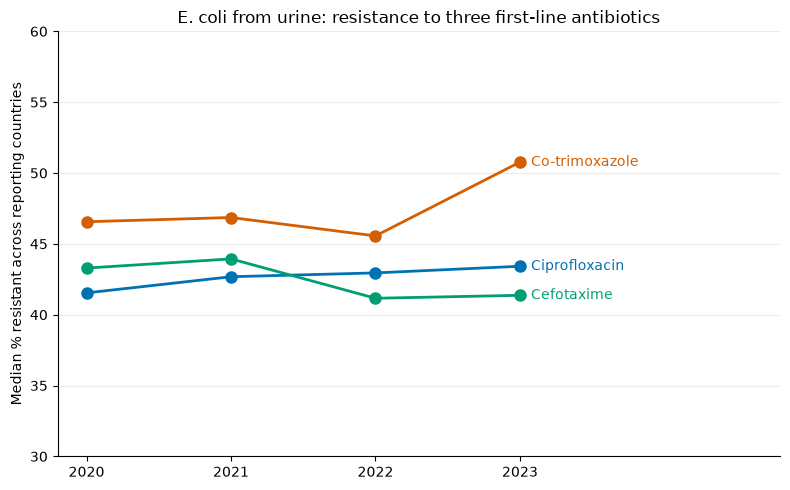

In [8]:
import matplotlib.pyplot as plt

FIGURES = Path("../figures")
COLOURS = {"Ciprofloxacin":  "#0072B2",
           "Co-trimoxazole": "#D55E00",
           "Cefotaxime":     "#009E73"}

fig, ax = plt.subplots(figsize=(8, 5))

for drug in DRUGS:
    d = summary[summary["AntibioticName"] == drug].sort_values("Year")
    ax.plot(d["Year"], d["median_pct"],
            color=COLOURS[drug], linewidth=2, marker="o", markersize=8)
    ax.annotate(drug,
                xy=(d["Year"].iloc[-1], d["median_pct"].iloc[-1]),
                xytext=(8, 0), textcoords="offset points",
                color=COLOURS[drug], va="center", fontsize=10)

ax.set_xticks([2020, 2021, 2022, 2023])
ax.set_xlim(2019.8, 2024.8)
ax.set_ylim(30, 60)
ax.set_ylabel("Median % resistant across reporting countries")
ax.set_title("E. coli from urine: resistance to three first-line antibiotics")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES / "01_median_resistance_trend.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Hold the country set fixed

Restricting to countries that reported in all four years, so only resistance
can move the line.

In [9]:
panels = {}
for drug in DRUGS:
    d = ok[ok["AntibioticName"] == drug]
    per_year = [set(d.loc[d["Year"] == y, "Iso3"]) for y in sorted(d["Year"].unique())]
    panels[drug] = set.intersection(*per_year)
    print(f"{drug:<16} all four years: {len(panels[drug]):>3} countries")

Ciprofloxacin    all four years:  42 countries
Co-trimoxazole   all four years:  35 countries
Cefotaxime       all four years:  33 countries


In [10]:
rows = []
for drug in DRUGS:
    d = ok[(ok["AntibioticName"] == drug) & (ok["Iso3"].isin(panels[drug]))]
    for year, group in d.groupby("Year"):
        rows.append({"AntibioticName": drug,
                     "Year": year,
                     "countries": group["Iso3"].nunique(),
                     "balanced_pct": round(group["MyPct"].median(), 2)})

balanced = pd.DataFrame(rows)

comparison = summary.merge(balanced, on=["AntibioticName", "Year"],
                           suffixes=("_all", "_panel"))
comparison[["AntibioticName", "Year", "countries_all", "median_pct",
            "countries_panel", "balanced_pct"]]

,AntibioticName,Year,countries_all,median_pct,countries_panel,balanced_pct
0,Cefotaxime,2020,43,43.29,33,42.77
1,Cefotaxime,2021,43,43.94,33,43.94
2,Cefotaxime,2022,50,41.16,33,39.34
3,Cefotaxime,2023,59,41.37,33,41.10
4,Ciprofloxacin,2020,53,41.54,42,46.72
5,Ciprofloxacin,2021,55,42.68,42,44.51
6,Ciprofloxacin,2022,58,42.95,42,48.12
7,Ciprofloxacin,2023,69,43.42,42,47.09
8,Co-trimoxazole,2020,51,46.56,35,47.64
9,Co-trimoxazole,2021,53,46.86,35,52.12


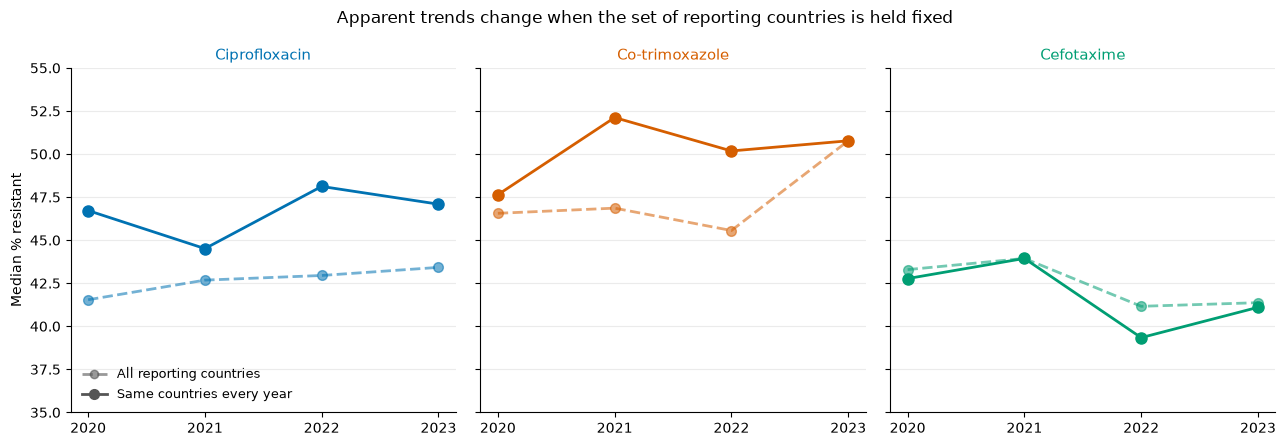

In [11]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

for ax, drug in zip(axes, DRUGS):
    d = comparison[comparison["AntibioticName"] == drug].sort_values("Year")
    colour = COLOURS[drug]
    ax.plot(d["Year"], d["median_pct"], color=colour, linewidth=2,
            linestyle="--", marker="o", markersize=7, alpha=0.55)
    ax.plot(d["Year"], d["balanced_pct"], color=colour, linewidth=2,
            marker="o", markersize=8)
    ax.set_title(drug, color=colour, fontsize=11)
    ax.set_xticks([2020, 2021, 2022, 2023])
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Median % resistant")
axes[0].set_ylim(35, 55)

handles = [Line2D([0], [0], color="#555555", lw=2, ls="--", marker="o", ms=6, alpha=0.6),
           Line2D([0], [0], color="#555555", lw=2, marker="o", ms=7)]
axes[0].legend(handles,
               ["All reporting countries", "Same countries every year"],
               frameon=False, fontsize=9, loc="lower left")

fig.suptitle("Apparent trends change when the set of reporting countries is held fixed",
             fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "02_balanced_panel_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
RESULTS = Path("../results")

summary.to_csv(RESULTS / "median_resistance_all_countries.csv", index=False)
comparison.to_csv(RESULTS / "all_countries_vs_balanced_panel.csv", index=False)

panel_sizes = pd.DataFrame([{"AntibioticName": d, "countries_in_panel": len(p)}
                            for d, p in panels.items()])
panel_sizes.to_csv(RESULTS / "balanced_panel_sizes.csv", index=False)

print(sorted(p.name for p in RESULTS.glob("*.csv")))

['all_countries_vs_balanced_panel.csv', 'balanced_panel_sizes.csv', 'four_ways_of_summarising.csv', 'median_resistance_all_countries.csv']


## 6. Weight by isolates, not countries

The median treats Germany's 588,000 isolates and Burundi's 20 as one vote each.
Total resistant over total tested asks a different question: what does the
typical tested isolate look like?

In [13]:
pooled = (ok.groupby(["AntibioticName", "Year"])
            .agg(countries=("Iso3", "nunique"),
                 median_pct=("MyPct", "median"),
                 resistant=("Resistant", "sum"),
                 tested=("InterpretableAST", "sum"))
            .reset_index())

pooled["pooled_pct"] = 100 * pooled["resistant"] / pooled["tested"]
pooled = pooled.round(2)
pooled[["AntibioticName", "Year", "countries", "median_pct", "pooled_pct", "tested"]]

,AntibioticName,Year,countries,median_pct,pooled_pct,tested
0,Cefotaxime,2020,43,43.29,14.19,1075655
1,Cefotaxime,2021,43,43.94,15.32,1196290
2,Cefotaxime,2022,50,41.16,16.39,1303872
3,Cefotaxime,2023,59,41.37,17.08,1497403
4,Ciprofloxacin,2020,53,41.54,16.31,2115381
5,Ciprofloxacin,2021,55,42.68,18.89,2191573
6,Ciprofloxacin,2022,58,42.95,20.59,2482516
7,Ciprofloxacin,2023,69,43.42,21.37,3103286
8,Co-trimoxazole,2020,51,46.56,21.97,1606166
9,Co-trimoxazole,2021,53,46.86,24.93,1619801


## 7. Test the change properly

Rather than testing four annual medians, test each country's own change from
2020 to 2023 — 42 paired observations instead of 4. Wilcoxon signed-rank, which
assumes nothing about the shape of the distribution.

In [14]:
from scipy.stats import wilcoxon

rows = []
for drug in DRUGS:
    d = ok[(ok["AntibioticName"] == drug) & (ok["Iso3"].isin(panels[drug]))]
    wide = d.pivot(index="Iso3", columns="Year", values="MyPct")
    change = wide[2023] - wide[2020]
    stat, p = wilcoxon(change)
    rows.append({"AntibioticName": drug,
                 "countries":     len(change),
                 "median_change": round(change.median(), 2),
                 "q1":            round(change.quantile(0.25), 2),
                 "q3":            round(change.quantile(0.75), 2),
                 "rose":          int((change > 0).sum()),
                 "fell":          int((change < 0).sum()),
                 "p_value":       round(p, 4)})

trend_test = pd.DataFrame(rows)
trend_test

,AntibioticName,countries,median_change,q1,q3,rose,fell,p_value
0,Ciprofloxacin,42,0.70,-1.03,4.35,26,16,0.0845
1,Co-trimoxazole,35,-0.96,-3.52,2.49,12,23,0.3592
2,Cefotaxime,33,-0.36,-2.20,3.18,16,17,0.7509


## 8. How much do countries differ from each other?

A median is a poor description of a distribution this wide.

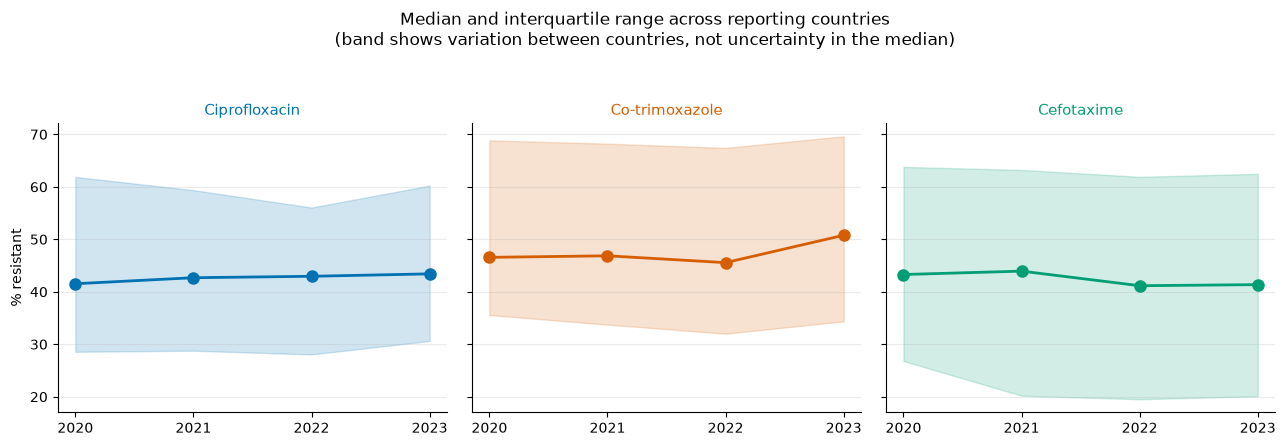

In [15]:
spread = (ok.groupby(["AntibioticName", "Year"])["MyPct"]
            .agg(median="median",
                 q1=lambda s: s.quantile(0.25),
                 q3=lambda s: s.quantile(0.75))
            .reset_index())

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

for ax, drug in zip(axes, DRUGS):
    d = spread[spread["AntibioticName"] == drug].sort_values("Year")
    c = COLOURS[drug]
    ax.fill_between(d["Year"], d["q1"], d["q3"], color=c, alpha=0.18)
    ax.plot(d["Year"], d["median"], color=c, linewidth=2, marker="o", markersize=8)
    ax.set_title(drug, color=c, fontsize=11)
    ax.set_xticks([2020, 2021, 2022, 2023])
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("% resistant")
fig.suptitle("Median and interquartile range across reporting countries\n"
             "(band shows variation between countries, not uncertainty in the median)",
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIGURES / "03_median_with_iqr.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
rows = []
for drug in DRUGS:
    d = ok[(ok["AntibioticName"] == drug) & (ok["Iso3"].isin(panels[drug]))]
    g = d.groupby("Year").agg(resistant=("Resistant", "sum"),
                              tested=("InterpretableAST", "sum"))
    for year, r in g.iterrows():
        rows.append({"AntibioticName": drug,
                     "Year": year,
                     "pooled_panel_pct": round(100 * r["resistant"] / r["tested"], 2),
                     "tested": int(r["tested"])})

pooled_panel = pd.DataFrame(rows)

final = (pooled[["AntibioticName", "Year", "median_pct", "pooled_pct"]]
         .merge(balanced[["AntibioticName", "Year", "balanced_pct"]],
                on=["AntibioticName", "Year"])
         .merge(pooled_panel[["AntibioticName", "Year", "pooled_panel_pct"]],
                on=["AntibioticName", "Year"]))

final.to_csv(RESULTS / "four_ways_of_summarising.csv", index=False)
final

,AntibioticName,Year,median_pct,pooled_pct,balanced_pct,pooled_panel_pct
0,Cefotaxime,2020,43.29,14.19,42.77,13.98
1,Cefotaxime,2021,43.94,15.32,43.94,14.96
2,Cefotaxime,2022,41.16,16.39,39.34,16.19
3,Cefotaxime,2023,41.37,17.08,41.10,16.42
4,Ciprofloxacin,2020,41.54,16.31,46.72,16.45
5,Ciprofloxacin,2021,42.68,18.89,44.51,17.93
6,Ciprofloxacin,2022,42.95,20.59,48.12,19.06
7,Ciprofloxacin,2023,43.42,21.37,47.09,20.61
8,Co-trimoxazole,2020,46.56,21.97,47.64,24.04
9,Co-trimoxazole,2021,46.86,24.93,52.12,25.87


## 9. Hold the weights fixed too

The pooled estimate re-weights countries every year by how much they tested that
year, so a country scaling up its laboratory moves the global figure without its
resistance changing. Freezing the weights at 2020 volumes removes that.

In [17]:
rows = []
for drug in DRUGS:
    d = ok[(ok["AntibioticName"] == drug) & (ok["Iso3"].isin(panels[drug]))]
    pct = d.pivot(index="Iso3", columns="Year", values="MyPct")
    n   = d.pivot(index="Iso3", columns="Year", values="InterpretableAST")

    weights = n[2020] / n[2020].sum()        # frozen at 2020 testing volumes

    for year in sorted(pct.columns):
        rows.append({"AntibioticName": drug,
                     "Year": year,
                     "fixed_weight_pct": round((weights * pct[year]).sum(), 2)})

fixed = pd.DataFrame(rows)

final2 = final.merge(fixed, on=["AntibioticName", "Year"])
final2.to_csv(RESULTS / "four_ways_of_summarising.csv", index=False)
final2

,AntibioticName,Year,median_pct,pooled_pct,balanced_pct,pooled_panel_pct,fixed_weight_pct
0,Cefotaxime,2020,43.29,14.19,42.77,13.98,13.98
1,Cefotaxime,2021,43.94,15.32,43.94,14.96,13.01
2,Cefotaxime,2022,41.16,16.39,39.34,16.19,13.18
3,Cefotaxime,2023,41.37,17.08,41.10,16.42,13.45
4,Ciprofloxacin,2020,41.54,16.31,46.72,16.45,16.45
5,Ciprofloxacin,2021,42.68,18.89,44.51,17.93,15.47
6,Ciprofloxacin,2022,42.95,20.59,48.12,19.06,15.56
7,Ciprofloxacin,2023,43.42,21.37,47.09,20.61,16.49
8,Co-trimoxazole,2020,46.56,21.97,47.64,24.04,24.04
9,Co-trimoxazole,2021,46.86,24.93,52.12,25.87,22.67


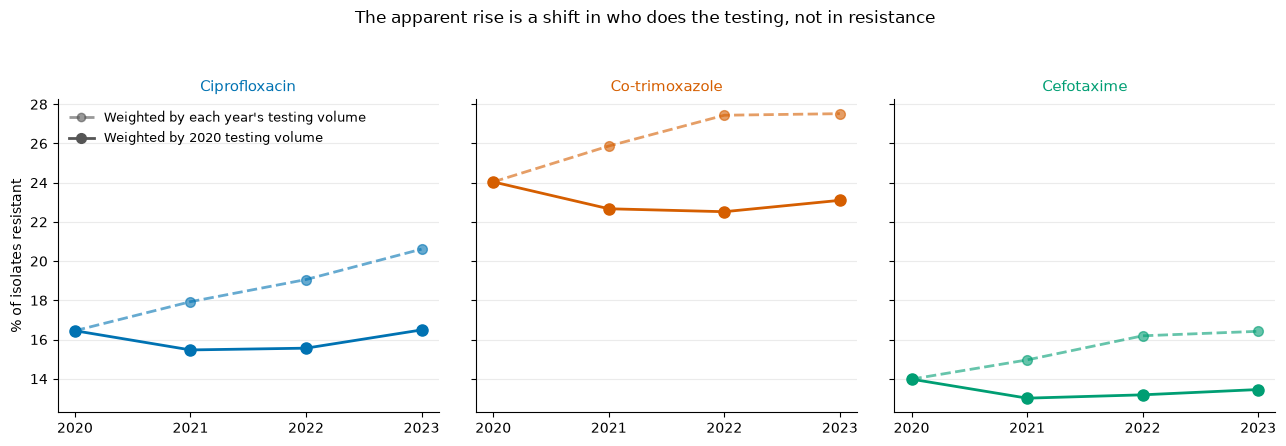

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

for ax, drug in zip(axes, DRUGS):
    d = final2[final2["AntibioticName"] == drug].sort_values("Year")
    c = COLOURS[drug]
    ax.plot(d["Year"], d["pooled_panel_pct"], color=c, lw=2, ls="--",
            marker="o", ms=7, alpha=0.6)
    ax.plot(d["Year"], d["fixed_weight_pct"], color=c, lw=2, marker="o", ms=8)
    ax.set_title(drug, color=c, fontsize=11)
    ax.set_xticks([2020, 2021, 2022, 2023])
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("% of isolates resistant")

handles = [Line2D([0], [0], color="#555555", lw=2, ls="--", marker="o", ms=6, alpha=0.6),
           Line2D([0], [0], color="#555555", lw=2, marker="o", ms=7)]
axes[0].legend(handles,
               ["Weighted by each year's testing volume",
                "Weighted by 2020 testing volume"],
               frameon=False, fontsize=9, loc="upper left")

fig.suptitle("The apparent rise is a shift in who does the testing, not in resistance",
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIGURES / "04_fixed_vs_floating_weights.png", dpi=200, bbox_inches="tight")
plt.show()

## Findings

1. No detectable change in any of the three antibiotics, 2020–2023, within
   countries reporting throughout (Wilcoxon, all p > 0.08).
2. Apparent rises come from two artefacts: which countries report, and how much
   each country tests.
3. The four summaries differ by more than twenty percentage points, because each
   describes a different population.